# Object detection and instance segmentation (PyTorch + MPS)

This notebook trains two small models on synthetic scenes:

1. **Anchor-based object detection (YOLO style) on urban / coastal scenes.**
   The image is split into a `24 x 24` grid; each cell predicts **6 anchor
   boxes** of different sizes. We detect six classes — **building, rock, tree,
   car, boat, parking** — in a dataset of mostly dense **urban** blocks with some
   **urban-fringe** and **coastal (beach)** scenes.
2. **Instance segmentation with a per-anchor mask head.** The detector is
   extended into a **multi-head** model: objectness and box heads plus an
   **extra mask head per anchor** that predicts a small instance mask, upscaled
   to the predicted box. It **counts trees** and **separates partially
   overlapping canopies** of a forest dataset.

Training uses random **flips** (images and targets together) and keeps the best
checkpoint, which lifts detection mAP and instance IoU. Both models run on Apple
**MPS** in a few minutes.


## Learning objectives

By the end of this notebook you will be able to:

- encode objects as **anchor-based detection targets** (objectness, class, box);
- choose **anchors** with k-means on the training box shapes;
- train a detector with a **multi-task loss** and evaluate it with **mAP@0.5**
  (score threshold, per-class NMS, greedy matching);
- extend the detector with a **mask head per anchor** and evaluate the
  instance masks with **IoU** and **count MAE**;
- read **instance IoU** and **count MAE** for overlapping tree crowns.

### Exercises

1. Why does mAP@0.5 change when you raise the NMS threshold? Try 0.3 and 0.7.
2. Lower `score_threshold` in `decode_anchor`: what happens to the count and to
   the instance IoU?
3. Raise `MASK_SIZE`: does the IoU improve, and at what training cost?

**What to expect.** (1) A higher NMS threshold keeps more overlapping boxes, so
duplicate detections survive and precision (hence mAP) falls; a lower threshold
removes more, risking misses on close objects like parked cars. (2) A lower
`score_threshold` reports more objects (higher count) with more false positives,
so recall rises while precision and instance IoU fall. (3) A larger `MASK_SIZE`
sharpens mask boundaries and usually gives a small IoU gain, at a memory/time
cost in the mask head.


### Key terms

- **anchor** — a prototypical box shape; each `(cell, anchor)` is one prediction
  slot.
- **objectness** — the score that a slot contains an object.
- **NMS** — non-maximum suppression; removes duplicate boxes of the same class.
- **AP / mAP** — area under the per-class precision-recall curve, and its mean
  over classes, at a given IoU threshold.
- **IoU threshold** — how much overlap counts as a correct detection (0.5 =
  mAP@0.5).
- **box-relative (instance) mask** — a mask predicted inside an object's own box,
  cropped and resized to `MASK_SIZE`.
- **count MAE / MAPE** — mean absolute / relative error of the predicted tree
  count.


In [1]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import copy
import time

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

FAST = False  # set True for a quick smoke run (fewer samples / epochs)
def pick_device():
    """Best available device: CUDA, then Apple MPS, then Intel XPU, else CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return "mps"
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return "xpu"
    return "cpu"


DEVICE = pick_device()
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("No GPU backend available: training will run on CPU (slower).")


torch 2.14.0 | device mps


## Detection dataset

We focus on six classes that occur in **urban and coastal** scenes:

| class | scene labels |
|---|---|
| building | building, silo |
| rock | rock |
| tree | tree, conifer, bush, orchard |
| car | car, truck, bus |
| boat | boat |
| parking | parking |

Most scenes are dense **urban** blocks (buildings, cars, parking lots, street
trees); **urban-fringe** scenes add low-rise buildings and greenery, and
**coastal** scenes add a sandy beach with boats and shoreline rocks. Each image
is `96 x 96`, the grid is `24 x 24` (stride 4) and we keep at most 16 objects per
image.


In [2]:
from mlpsyn.scene import generate_scene
from mlpsyn.sensor import apply_sensor

SIZE = 96
GRID = 24
N_ANCHORS = 6
N_SAMPLES, N_VAL, N_TEST = (180, 40, 32) if FAST else (480, 80, 64)
MAX_OBJECTS = 24  # keep the many small cars

LABEL_MAP = {
    "building": "building", "silo": "building",
    "rock": "rock",
    "tree": "tree", "conifer": "tree", "bush": "tree", "orchard": "tree",
    "car": "car", "truck": "car", "bus": "car",
    "boat": "boat",
    "parking": "parking",
    "breakwater": "rock",   # rubble moles read as rock from above
    "pier": "building",     # long waterfront structures
    "marina": "parking",    # sheltered basin full of moored boats
}
CLASSES = ["building", "rock", "tree", "car", "boat", "parking"]
CLASS_INDEX = {name: idx for idx, name in enumerate(CLASSES)}
# Mostly urban cities, with some urban fringe and coastal (beach) scenes.
SCENE_TYPES = [
    "urban", "urban", "urban", "urban", "urban_fringe", "urban_fringe",
    "coastal", "coastal", "coastal_city", "coastal_city",
]


def degrade_image(image, rng):
    """Small realistic sensor noise; ~20% of images get partial cloud cover.

    Labels/boxes come from the clean scene, so they stay valid under the noise:
    the model just has to be robust to it. Most images are only lightly degraded.
    """
    if rng.random() < 0.4:
        return apply_sensor(
            image, rng, kind="poisson", blur_radius=0.5,
            haze_strength=0.06, cloud_coverage=rng.uniform(0.25, 0.5),
            cloud_opacity=0.55,
        )
    if rng.random() < 0.5:
        return apply_sensor(
            image, rng, kind="poisson" if rng.random() < 0.5 else None,
            blur_radius=rng.uniform(0.0, 0.4), haze_strength=rng.uniform(0.0, 0.06),
        )
    return image.copy()


def make_data(n_samples, seed=0):
    rng = np.random.default_rng(seed)
    images, objects_per_image = [], []
    for _ in range(n_samples):
        scene_name = SCENE_TYPES[int(rng.integers(len(SCENE_TYPES)))]
        scene_seed = int(rng.integers(10_000))
        scene = generate_scene(scene_name, size=SIZE, seed=scene_seed)
        image = degrade_image(scene.image, rng)   # keep boxes from the clean scene
        objects = [obj for obj in scene.objects if obj.label in LABEL_MAP]
        objects.sort(key=lambda obj: -((obj.bbox[2] - obj.bbox[0]) * (obj.bbox[3] - obj.bbox[1])))
        images.append(image)
        objects_per_image.append(objects[:MAX_OBJECTS])
    image_tensor = torch.from_numpy(
        np.stack(images).astype(np.float32).transpose(0, 3, 1, 2) / 255.0
    )
    return image_tensor, objects_per_image


started = time.time()
images, objects_per_image = make_data(N_SAMPLES)
print("images", tuple(images.shape), "| generated in", round(time.time() - started, 1), "s")


images (480, 3, 96, 96) | generated in 34.6 s


## Anchor boxes (k-means)

Anchor boxes are prototypes of object shapes. Instead of one box per cell we
use **A = 6 anchors per cell**, giving `24 * 24 * 6 = 3456` predictions per
image. We pick the anchors with **scikit-learn's KMeans** (`n_init=10`) on the
`(width, height)` of the training boxes, so the result is stable across runs. This lets different anchors specialise in small, medium or large
(and wide or tall) objects. Because sizes span more than an order of magnitude,
the clustering runs on `(log width, log height)` — clustering raw sizes lets the
few large boxes dominate and starves the small-object anchors. The forest trees
have a narrow size range, so there `log_space=False` (raw clustering) is used.


In [3]:
def shape_iou(box_wh, anchor_wh):
    """Intersection-over-union of two centred boxes given as (width, height)."""
    width, height = box_wh
    anchor_w, anchor_h = anchor_wh
    intersection = min(width, anchor_w) * min(height, anchor_h)
    union = width * height + anchor_w * anchor_h - intersection
    return intersection / union if union > 0 else 0.0


def kmeans_anchors(boxes_wh, n_anchors, seed=0, log_space=True):
    """Cluster training box shapes into ``n_anchors`` (width, height) anchors.

    With ``log_space=True`` the clustering runs on ``(log w, log h)``: box sizes
    span more than an order of magnitude, and clustering raw widths/heights is
    dominated by the few large boxes, which starves the small-object anchors.
    For a narrow size range (the uniform forest crowns) raw clustering is fine,
    so pass ``log_space=False`` there. Uses scikit-learn's
    :class:`~sklearn.cluster.KMeans` with ``n_init=10`` so the anchors do not
    depend on a single random initialisation.
    """
    boxes_wh = np.asarray(boxes_wh, dtype=float)
    features = np.log(np.clip(boxes_wh, 1e-4, None)) if log_space else boxes_wh
    kmeans = KMeans(n_clusters=n_anchors, n_init=10, random_state=seed)
    kmeans.fit(features)
    anchors = np.exp(kmeans.cluster_centers_) if log_space else kmeans.cluster_centers_
    return np.sort(anchors, axis=0)


training_boxes = [
    (obj.bbox[2] - obj.bbox[0], obj.bbox[3] - obj.bbox[1])
    for objects in objects_per_image[: N_SAMPLES - N_VAL]
    for obj in objects
]
ANCHORS = kmeans_anchors(training_boxes, N_ANCHORS)
print("boxes:", len(training_boxes))
for anchor_idx, (anchor_w, anchor_h) in enumerate(ANCHORS):
    print(f"anchor {anchor_idx}: width {anchor_w:.3f} height {anchor_h:.3f}")


boxes: 5990
anchor 0: width 0.046 height 0.045
anchor 1: width 0.047 height 0.059
anchor 2: width 0.061 height 0.061
anchor 3: width 0.100 height 0.098
anchor 4: width 0.154 height 0.153
anchor 5: width 0.539 height 0.166


## Encoding targets

For every ground-truth box we choose the anchor with the best **shape IoU** and
the grid cell that contains its centre. That `(cell, anchor)` slot becomes a
positive and stores:

- `objectness = 1`;
- the one-hot class;
- box targets `tx, ty, tw, th` with

$$t_x = c_x S - \text{col},\quad t_y = (1-c_y)S - \text{row},\quad
t_w = \log\frac{w}{a_w},\quad t_h = \log\frac{h}{a_h}.$$

At inference we invert them:

$$b_x = \frac{\text{col}+\sigma(t_x)}{S},\quad
b_y = 1-\frac{\text{row}+\sigma(t_y)}{S},\quad
b_w = a_w e^{t_w},\quad b_h = a_h e^{t_h}.$$


In [4]:
def encode_targets(objects, anchors):
    """Encode scene objects into YOLO-style (objectness, class, box) targets.

    Each object goes to the anchor with the best shape IoU and to the grid cell
    holding its centre; the box target is the in-cell centre offset plus the log
    size ratio to the anchor.
    """
    n_anchors = len(anchors)
    objectness = np.zeros((GRID, GRID, n_anchors), np.float32)
    class_target = np.zeros((GRID, GRID, n_anchors, len(CLASSES)), np.float32)
    box_target = np.zeros((GRID, GRID, n_anchors, 4), np.float32)
    for obj in objects:
        class_idx = CLASS_INDEX[LABEL_MAP[obj.label]]
        x0, y0, x1, y1 = obj.bbox
        width, height = x1 - x0, y1 - y0
        if width <= 0 or height <= 0:
            continue  # skip degenerate (clipped-out) boxes
        center_x, center_y = (x0 + x1) / 2, (y0 + y1) / 2
        anchor_idx = int(np.argmax([shape_iou((width, height), a) for a in anchors]))
        col = int(np.clip(center_x * GRID, 0, GRID - 1))
        row = int(np.clip((1 - center_y) * GRID, 0, GRID - 1))
        objectness[row, col, anchor_idx] = 1
        class_target[row, col, anchor_idx, class_idx] = 1
        box_target[row, col, anchor_idx] = [
            center_x * GRID - col,
            (1 - center_y) * GRID - row,
            np.log(width / anchors[anchor_idx][0]),
            np.log(height / anchors[anchor_idx][1]),
        ]
    return objectness, class_target, box_target


objectness, class_target, box_target = [], [], []
for objects in objects_per_image:
    o, c, b = encode_targets(objects, ANCHORS)
    objectness.append(o); class_target.append(c); box_target.append(b)
objectness = torch.from_numpy(np.stack(objectness))
class_target = torch.from_numpy(np.stack(class_target))
box_target = torch.from_numpy(np.stack(box_target))

# train / validation (model selection) / test (reported once).
cut = N_VAL + N_TEST
train_images, val_images, test_images = images[:-cut], images[-cut:-N_TEST], images[-N_TEST:]
train_objectness, val_objectness = objectness[:-cut], objectness[-cut:-N_TEST]
train_class, val_class = class_target[:-cut], class_target[-cut:-N_TEST]
train_box, val_box = box_target[:-cut], box_target[-cut:-N_TEST]
train_objects = objects_per_image[:-cut]
val_objects, test_objects = objects_per_image[-cut:-N_TEST], objects_per_image[-N_TEST:]

def _targets(objects_per_image):
    return [[(LABEL_MAP[obj.label], obj.bbox) for obj in objects] for objects in objects_per_image]

ground_truths = _targets(val_objects)
test_ground_truths = _targets(test_objects)
print("train", tuple(train_images.shape), "val", tuple(val_images.shape))
print("positives per train image:", float(objectness[:-N_VAL].sum()) / (N_SAMPLES - N_VAL))


train (336, 3, 96, 96) val (80, 3, 96, 96)
positives per train image: 14.4475


## Loss and metric values on toy data (no model yet)

**Losses** (all summed, with weights):
- objectness: BCE-with-logits over *all* cells with a `pos_weight` to counter
  the huge number of negatives;
- class: BCE-with-logits only on positive slots;
- box: Smooth-L1 on `(tx,ty,tw,th)` only on positive slots.

### Why BCE for a *multi-class* head?

Yes - **BCE = binary cross-entropy**, applied **once per class**, independently.
The class head emits `C` numbers per slot and the loss treats each as its own
yes/no question:

$$\mathcal{L}_{\text{class}} = -\frac{1}{P}\sum_{p=1}^{P}\sum_{c=1}^{C}
\big[y_{pc}\log\sigma(z_{pc}) + (1-y_{pc})\log(1-\sigma(z_{pc}))\big],
\qquad \sigma(z)=\frac{1}{1+e^{-z}},$$

where `P` is the number of positive slots and `y` is one-hot (exactly one class
is 1). At inference we take `argmax_c z_c`, so mutual exclusivity is enforced
*there*, not by a softmax.

The alternative is **softmax + categorical cross-entropy**, which couples the
`C` logits so they compete and sum to 1; that is the textbook choice for
mutually-exclusive single-label classes. We use independent sigmoid + BCE
because it is the standard one-stage-detector convention (YOLO/FCOS): the
classes do not compete, so the same head generalises to **multi-label** targets
and classes can be added or removed without retraining the others.

**Metrics:** a detection is a true positive when its IoU with an unmatched box
of the same class is >= 0.5; AP is the area under the precision-recall curve and
mAP@0.5 averages AP over classes (greedy matching, as in `mlpsyn.metrics`).


In [5]:
# Which anchor does a "wide" box pick, and what are its targets?
example_width, example_height = 0.34, 0.16
for anchor_idx, (anchor_w, anchor_h) in enumerate(ANCHORS):
    print(f"anchor {anchor_idx}: shape IoU {shape_iou((example_width, example_height), (anchor_w, anchor_h)):.3f}")
chosen = int(np.argmax([shape_iou((example_width, example_height), a) for a in ANCHORS]))
print("chosen anchor:", chosen)

# Toy objectness logits: one confident positive, two negatives.
example_objectness = torch.tensor([[6.0, -3.0], [-2.0, -4.0]])
example_objectness_target = torch.tensor([[1.0, 0.0], [0.0, 0.0]])
print("objectness BCE:",
      round(float(F.binary_cross_entropy_with_logits(
          example_objectness, example_objectness_target, pos_weight=torch.tensor(5.0))), 3))
manually = -(
    example_objectness_target * torch.log(torch.sigmoid(example_objectness))
    + (1 - example_objectness_target) * torch.log(1 - torch.sigmoid(example_objectness))
).mean()
print("manual BCE:    ", round(float(manually), 3))


anchor 0: shape IoU 0.039
anchor 1: shape IoU 0.051
anchor 2: shape IoU 0.067
anchor 3: shape IoU 0.180
anchor 4: shape IoU 0.432
anchor 5: shape IoU 0.606
chosen anchor: 5
objectness BCE: 0.052
manual BCE:     0.049


### Where do the boxes go? (visual)

The targets are abstract `(cell, anchor)` slots. The figure below makes the
encoding concrete: for a few training images it draws each ground-truth box
(green), the **grid cell** its centre falls in (cyan outline) and the **anchor
index** it matched by shape IoU (labelled `aK`). Each object therefore becomes
exactly one positive slot — the one whose anchor shape is closest to it.

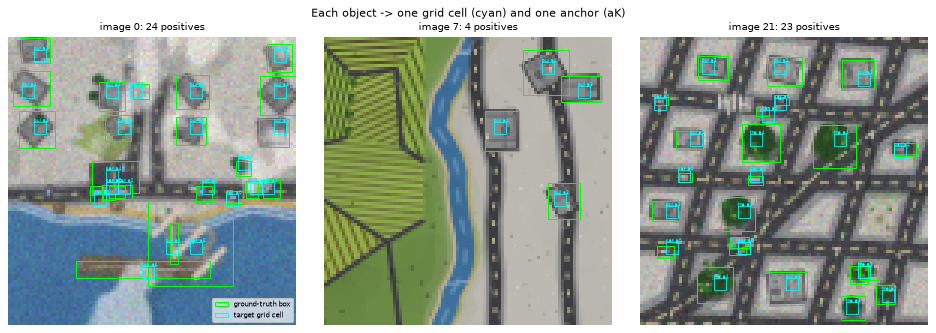

In [6]:
import matplotlib.patches as mpatches
def assigned_slots(objects):
    """Return (class, box, anchor_idx, col, row) for every usable object."""
    slots = []
    for obj in objects:
        x0, y0, x1, y1 = obj.bbox
        width, height = x1 - x0, y1 - y0
        if width <= 0 or height <= 0:
            continue
        anchor_idx = int(np.argmax([shape_iou((width, height), a) for a in ANCHORS]))
        centre_x, centre_y = (x0 + x1) / 2, (y0 + y1) / 2
        col = int(np.clip(centre_x * GRID, 0, GRID - 1))
        row = int(np.clip((1 - centre_y) * GRID, 0, GRID - 1))
        slots.append((LABEL_MAP[obj.label], obj.bbox, anchor_idx, col, row))
    return slots


cell_size = SIZE / GRID
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), dpi=80)
for ax, sample_index in zip(axes, (0, 7, 21)):
    ax.imshow(images[sample_index].permute(1, 2, 0))
    for name, (x0, y0, x1, y1), anchor_idx, col, row in assigned_slots(objects_per_image[sample_index]):
        # ground-truth box
        ax.add_patch(mpatches.Rectangle((x0 * SIZE, (1 - y1) * SIZE), (x1 - x0) * SIZE, (y1 - y0) * SIZE,
                     edgecolor="lime", facecolor="none", linewidth=0.9))
        # target grid cell (row counts from the top)
        ax.add_patch(mpatches.Rectangle((col * cell_size, row * cell_size), cell_size, cell_size,
                     edgecolor="cyan", facecolor="none", linewidth=0.7))
        ax.text(col * cell_size, row * cell_size, f"{name[:3]} a{anchor_idx}", color="cyan", fontsize=4.5)
    ax.set_title(f"image {sample_index}: {len(assigned_slots(objects_per_image[sample_index]))} positives", fontsize=9)
    ax.axis("off")
axes[0].legend(handles=[mpatches.Patch(facecolor="none", edgecolor="lime", label="ground-truth box"),
                        mpatches.Patch(facecolor="none", edgecolor="cyan", label="target grid cell")],
               loc="lower right", fontsize=6, framealpha=0.7)
plt.suptitle("Each object -> one grid cell (cyan) and one anchor (aK)", fontsize=10)
plt.tight_layout()
plt.show()


**Figure read-out.** Each ground-truth box (green), the grid cell its centre falls in (cyan) and the matched anchor index (`aK`). Every object becomes exactly one `(cell, anchor)` slot; dense urban images contain many positives.

In [7]:
def box_iou(box_a, box_b):
    """IoU of two (x0, y0, x1, y1) boxes (bottom-left origin)."""
    left = max(box_a[0], box_b[0]); bottom = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2]); top = min(box_a[3], box_b[3])
    intersection = max(0.0, right - left) * max(0.0, top - bottom)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def non_max_suppression(detections, iou_threshold=0.5):
    """Greedily keep the top-scoring boxes, dropping same-class overlaps."""
    # detections: [score, class_idx, x0, y0, x1, y1], highest score first.
    detections = sorted(detections, key=lambda det: -det[0])
    kept = []
    for det in detections:
        suppressed = any(
            other[1] == det[1] and box_iou(other[2:], det[2:]) > iou_threshold
            for other in kept
        )
        if not suppressed:
            kept.append(det)
    return kept


def decode_predictions(predictions, anchors, score_threshold=0.05, top_k=20, iou_threshold=0.5):
    """Turn raw head outputs into per-image [(class, score, box), ...]."""
    objectness = torch.sigmoid(predictions[..., 0])
    class_probs = torch.sigmoid(predictions[..., 5:])
    tx = torch.sigmoid(predictions[..., 1]); ty = torch.sigmoid(predictions[..., 2])
    tw = predictions[..., 3]; th = predictions[..., 4]
    results = []
    for image_idx in range(len(predictions)):
        candidates = []
        for anchor_idx, (anchor_w, anchor_h) in enumerate(anchors):
            for row in range(GRID):
                for col in range(GRID):
                    class_idx = int(class_probs[image_idx, row, col, anchor_idx].argmax())
                    score = float(objectness[image_idx, row, col, anchor_idx]) * float(
                        class_probs[image_idx, row, col, anchor_idx, class_idx])
                    if score < score_threshold:
                        continue
                    center_x = (col + float(tx[image_idx, row, col, anchor_idx])) / GRID
                    center_y = 1 - (row + float(ty[image_idx, row, col, anchor_idx])) / GRID
                    width = anchor_w * float(torch.exp(tw[image_idx, row, col, anchor_idx]))
                    height = anchor_h * float(torch.exp(th[image_idx, row, col, anchor_idx]))
                    candidates.append([
                        score, class_idx,
                        center_x - width / 2, center_y - height / 2,
                        center_x + width / 2, center_y + height / 2,
                    ])
        kept = non_max_suppression(candidates, iou_threshold)[:top_k]
        results.append([(CLASSES[c], s, x0, y0, x1, y1) for s, c, x0, y0, x1, y1 in kept])
    return results


def precision_recall_curve(detections, targets, class_name, iou_threshold=0.5):
    """Return (recall, precision, AP) for one class (greedy matching)."""
    n_positive = sum(1 for boxes in targets for name, _ in boxes if name == class_name)
    if n_positive == 0:
        return None, None, None
    ranked = sorted(
        [(score, image_idx, box)
         for image_idx, dets in enumerate(detections)
         for name, score, *box in dets if name == class_name],
        key=lambda item: -item[0],
    )
    matched = {image_idx: [False] * len(targets[image_idx]) for image_idx in range(len(targets))}
    true_positives, false_positives = [], []
    for _, image_idx, box in ranked:
        best_iou, best_idx = -1.0, -1
        for box_idx, (name, target_box) in enumerate(targets[image_idx]):
            if name == class_name and not matched[image_idx][box_idx]:
                iou = box_iou(box, target_box)
                if iou > best_iou:
                    best_iou, best_idx = iou, box_idx
        if best_iou >= iou_threshold:
            matched[image_idx][best_idx] = True
            true_positives.append(1); false_positives.append(0)
        else:
            true_positives.append(0); false_positives.append(1)
    if not true_positives:
        return np.array([0.0, 1.0]), np.array([0.0, 0.0]), 0.0
    true_positives = np.cumsum(true_positives); false_positives = np.cumsum(false_positives)
    recall = true_positives / n_positive
    precision = true_positives / (true_positives + false_positives)
    recall_curve = np.concatenate([[0], recall, [1]])
    precision_curve = np.concatenate([[0], precision, [0]])
    for k in range(len(precision_curve) - 2, -1, -1):
        precision_curve[k] = max(precision_curve[k], precision_curve[k + 1])
    steps = np.where(recall_curve[1:] != recall_curve[:-1])[0]
    average_precision_value = float(
        ((recall_curve[steps + 1] - recall_curve[steps]) * precision_curve[steps + 1]).sum())
    return recall_curve, precision_curve, average_precision_value


def average_precision(detections, targets, class_name, iou_threshold=0.5):
    """Area under the precision-recall curve for one class (greedy matching)."""
    return precision_recall_curve(detections, targets, class_name, iou_threshold)[2]


def mean_average_precision(detections, targets):
    """Mean AP@0.5 over the classes that appear in the targets."""
    per_class = {name: average_precision(detections, targets, name) for name in CLASSES}
    present = {name: value for name, value in per_class.items() if value is not None}
    return float(np.mean(list(present.values()))), per_class


## Model

A small convolutional backbone (`96 -> 48 -> 24`) followed by a `1 x 1`
head that outputs, for every cell, `A * (5 + C)` values: `1` objectness,
`4` box offsets and `C` class logits (shared weights across locations).


In [8]:
class AnchorDetector(nn.Module):
    """YOLO-style detector: a shared backbone plus one anchor-aware head."""

    def __init__(self, n_anchors, n_classes, base=32):
        super().__init__()

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.n_anchors = n_anchors
        self.n_classes = n_classes
        # Two stride-2 blocks downsample 96 -> 48 -> 24; the 1x1 head then
        # predicts, for every cell and anchor: 1 objectness + 4 box + C classes.
        self.backbone = nn.Sequential(block(3, base, 2), block(base, base * 2, 2))
        self.head = nn.Conv2d(base * 2, n_anchors * (5 + n_classes), 1)

    def forward(self, image_batch):
        features = self.backbone(image_batch)
        raw = self.head(features)
        # Reshape (B, A, 5+C, S, S) into per-cell predictions (B, S, S, A, 5+C).
        raw = raw.view(len(image_batch), self.n_anchors, 5 + self.n_classes, GRID, GRID)
        return raw.permute(0, 3, 4, 1, 2).contiguous()


model = AnchorDetector(N_ANCHORS, len(CLASSES)).to(DEVICE)
n_parameters = sum(p.numel() for p in model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


70.0 k parameters


## Training loop

We optimise `objectness + 2 * class + 2 * box` with AdamW. Each batch is randomly
flipped (horizontally / vertically, with the target tensor flipped the same way)
and given a per-image brightness / contrast jitter, which acts as strong augmentation so the model no longer overfits after
~30 epochs. Every 10 epochs we decode the validation set and keep the checkpoint
with the best mAP@0.5. The **training and validation loss curves** (plus
validation mAP@0.5) below show both losses falling, then flattening — the peak
of the mAP curve is the checkpoint we keep.


In [9]:
def flip_batch(images, objectness, class_target, box_target, rng):
    """Random horizontal / vertical flips; flip the targets to match."""
    if rng.random() < 0.5:  # horizontal flip: mirror columns, invert tx
        images = torch.flip(images, [3])
        objectness = torch.flip(objectness, [2]).clone()
        class_target = torch.flip(class_target, [2]).clone()
        box_target = torch.flip(box_target, [2]).clone()
        box_target[..., 0] = 1 - box_target[..., 0]
    if rng.random() < 0.5:  # vertical flip: mirror rows, invert ty
        images = torch.flip(images, [2])
        objectness = torch.flip(objectness, [1]).clone()
        class_target = torch.flip(class_target, [1]).clone()
        box_target = torch.flip(box_target, [1]).clone()
        box_target[..., 1] = 1 - box_target[..., 1]
    # Photometric jitter: per-image brightness / contrast.
    scale = torch.empty(len(images), 1, 1, 1).uniform_(0.8, 1.2)
    shift = torch.empty(len(images), 1, 1, 1).uniform_(-0.06, 0.06)
    images = torch.clamp(images * scale + shift, 0, 1)
    return images, objectness, class_target, box_target


optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
EPOCHS, BATCH_SIZE = (30 if FAST else 100), 16
POS_WEIGHT, CLASS_WEIGHT, BOX_WEIGHT = 5.0, 2.0, 2.0
pos_weight = torch.tensor(POS_WEIGHT, device=DEVICE)
rng = np.random.default_rng(0)

val_images_device = val_images.to(DEVICE)
val_objectness_device = val_objectness.to(DEVICE)
val_class_device = val_class.to(DEVICE)
val_box_device = val_box.to(DEVICE)
best_mean_ap, best_state = 0.0, None
history = []
started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images), device="cpu")
    running_loss = 0.0
    for start in range(0, len(train_images), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        batch_images, batch_objectness, batch_class, batch_box = flip_batch(
            train_images[batch_indices], train_objectness[batch_indices],
            train_class[batch_indices], train_box[batch_indices], rng)
        batch_images = batch_images.to(DEVICE)
        batch_objectness = batch_objectness.to(DEVICE)
        batch_class = batch_class.to(DEVICE)
        batch_box = batch_box.to(DEVICE)
        optimizer.zero_grad()
        # Forward pass: objectness / class / box logits for every cell and anchor.
        predictions = model(batch_images)
        objectness_logit = predictions[..., 0]
        class_logit = predictions[..., 5:]
        box_prediction = predictions[..., 1:5]
        # Only slots that contain an object contribute class / box gradients.
        positive_mask = batch_objectness > 0.5
        objectness_loss = F.binary_cross_entropy_with_logits(
            objectness_logit, batch_objectness, pos_weight=pos_weight)
        class_loss = F.binary_cross_entropy_with_logits(
            class_logit[positive_mask], batch_class[positive_mask])
        box_loss = F.smooth_l1_loss(
            box_prediction[positive_mask], batch_box[positive_mask])
        loss = objectness_loss + CLASS_WEIGHT * class_loss + BOX_WEIGHT * box_loss
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 10 == 9 or epoch == EPOCHS - 1:
        model.eval()
        with torch.no_grad():
            predictions = model(val_images_device)
            # Same multi-task loss as training, now on the held-out validation set.
            validation_positive = val_objectness_device > 0.5
            validation_objectness_loss = F.binary_cross_entropy_with_logits(
                predictions[..., 0], val_objectness_device, pos_weight=pos_weight)
            validation_class_loss = F.binary_cross_entropy_with_logits(
                predictions[..., 5:][validation_positive], val_class_device[validation_positive])
            validation_box_loss = F.smooth_l1_loss(
                predictions[..., 1:5][validation_positive], val_box_device[validation_positive])
            validation_loss = (validation_objectness_loss
                               + CLASS_WEIGHT * validation_class_loss
                               + BOX_WEIGHT * validation_box_loss).item()
        detections = decode_predictions(predictions.cpu(), ANCHORS)
        mean_ap, _ = mean_average_precision(detections, ground_truths)
        # Keep the checkpoint with the best validation mAP@0.5.
        if mean_ap > best_mean_ap:
            best_mean_ap = mean_ap
            best_state = copy.deepcopy(model.state_dict())
        history.append((epoch, running_loss / len(train_images), validation_loss, mean_ap))
        print(
            f"epoch {epoch:3d} | loss {running_loss/len(train_images):.3f}"
            f" | val loss {validation_loss:.3f} | mAP@0.5 {mean_ap:.3f}"
            f" | best {best_mean_ap:.3f} | {time.time()-started:.0f}s"
        )
model.load_state_dict(best_state)
print(f"best mAP@0.5 {best_mean_ap:.3f} | training time {time.time()-started:.1f} s")


epoch   9 | loss 0.252 | val loss 0.297 | mAP@0.5 0.078 | best 0.078 | 12s


epoch  19 | loss 0.142 | val loss 0.205 | mAP@0.5 0.211 | best 0.211 | 21s


epoch  29 | loss 0.098 | val loss 0.162 | mAP@0.5 0.329 | best 0.329 | 29s


epoch  39 | loss 0.079 | val loss 0.133 | mAP@0.5 0.438 | best 0.438 | 36s


epoch  49 | loss 0.067 | val loss 0.147 | mAP@0.5 0.427 | best 0.438 | 45s


epoch  59 | loss 0.060 | val loss 0.124 | mAP@0.5 0.472 | best 0.472 | 52s


epoch  69 | loss 0.054 | val loss 0.121 | mAP@0.5 0.497 | best 0.497 | 60s


epoch  79 | loss 0.052 | val loss 0.121 | mAP@0.5 0.515 | best 0.515 | 68s


epoch  89 | loss 0.047 | val loss 0.164 | mAP@0.5 0.483 | best 0.515 | 75s


epoch  99 | loss 0.044 | val loss 0.125 | mAP@0.5 0.501 | best 0.515 | 83s
best mAP@0.5 0.515 | training time 82.8 s


## Data augmentation, visualised

The training loop augments every batch with random **flips** (horizontal /
vertical) and a **brightness / contrast jitter**. A flip is label-preserving
because mirroring the image mirrors each box with it; the photometric jitter
changes only brightness, so the geometry is untouched. The grid below shows
one training image under each transform, with the boxes transformed the same
way — the targets remain valid.

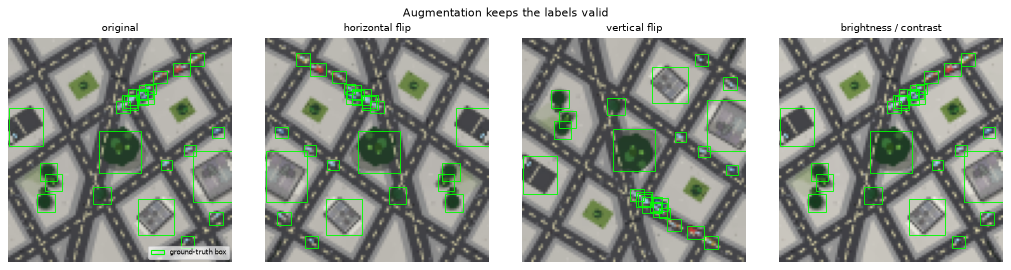

In [10]:
import matplotlib.patches as mpatches


def draw_scene_boxes(ax, boxes, color="lime"):
    """Draw (class, (x0, y0, x1, y1)) boxes in bottom-left scene coords."""
    for _name, (x0, y0, x1, y1) in boxes:
        ax.add_patch(mpatches.Rectangle(
            (x0 * SIZE, (1 - y1) * SIZE), (x1 - x0) * SIZE, (y1 - y0) * SIZE,
            edgecolor=color, facecolor="none", linewidth=0.8))


def horizontal_flip(image, boxes):
    """Mirror left-right; mirror every box the same way (x -> 1 - x)."""
    return torch.flip(image, [2]), [(n, (1 - x1, y0, 1 - x0, y1)) for n, (x0, y0, x1, y1) in boxes]


def vertical_flip(image, boxes):
    """Mirror top-bottom; mirror every box the same way (y -> 1 - y)."""
    return torch.flip(image, [1]), [(n, (x0, 1 - y1, x1, 1 - y0)) for n, (x0, y0, x1, y1) in boxes]


def brightness_contrast(image, seed=0):
    """The photometric jitter from the training loop (geometry unchanged)."""
    generator = torch.Generator().manual_seed(seed)
    scale = torch.empty(1, 1, 1).uniform_(0.8, 1.2, generator=generator)
    shift = torch.empty(1, 1, 1).uniform_(-0.06, 0.06, generator=generator)
    return torch.clamp(image * scale + shift, 0, 1)


sample_index = 2
sample_image = images[sample_index]
sample_boxes = [(LABEL_MAP[obj.label], obj.bbox) for obj in objects_per_image[sample_index]]
variants = [
    ("original", sample_image, sample_boxes),
    ("horizontal flip", *horizontal_flip(sample_image, sample_boxes)),
    ("vertical flip", *vertical_flip(sample_image, sample_boxes)),
    ("brightness / contrast", brightness_contrast(sample_image, seed=1), sample_boxes),
]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), dpi=80)
for ax, (title, image, boxes) in zip(axes, variants):
    ax.imshow(image.permute(1, 2, 0))
    draw_scene_boxes(ax, boxes)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
axes[0].legend(handles=[mpatches.Patch(facecolor="none", edgecolor="lime", label="ground-truth box")],
               loc="lower right", fontsize=6, framealpha=0.7)
plt.suptitle("Augmentation keeps the labels valid", fontsize=10)
plt.tight_layout()
plt.show()


**Figure read-out.** One training image under horizontal flip, vertical flip and brightness/contrast, with the boxes transformed identically - the labels stay valid.

## Detection evaluation

Final mAP@0.5 per class (evaluated with the best checkpoint), the **training
curves** (loss and validation mAP@0.5 vs epoch) and a few validation images with
ground truth (green) and predictions (red). We also print the **no-object
baseline** (mAP 0): the metric is only meaningful between that floor and a
perfect oracle (mAP 1). **Per-class precision-recall curves** show what the
single mAP number averages.


/var/folders/93/0_k_9bh97fj_15hzk2bhy5r00000gn/T/ipykernel_19474/1194061253.py:40: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  score = float(objectness[image_idx, row, col, anchor_idx]) * float(


validation mAP@0.5 = 0.515
test       mAP@0.5 = 0.497   <- reported once, never used for tuning
per-class AP@0.5:
  building    0.711
  rock        0.463
  tree        0.450
  car         0.157
  boat        0.731
  parking     0.577
no-object baseline      mAP@0.5 = 0.000


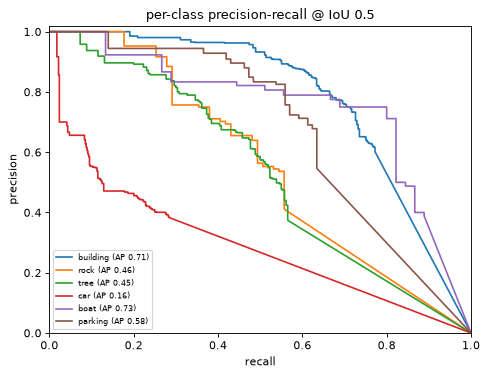

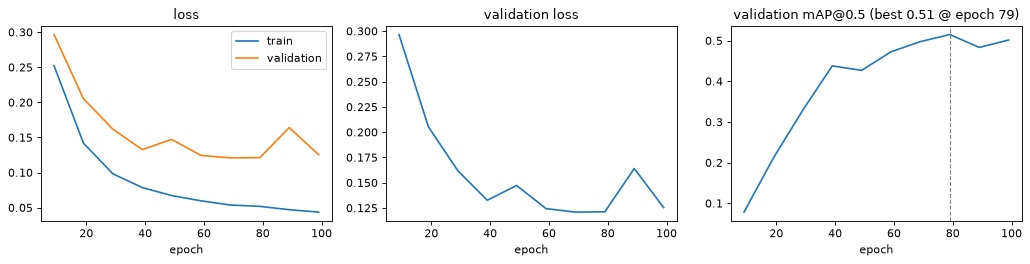

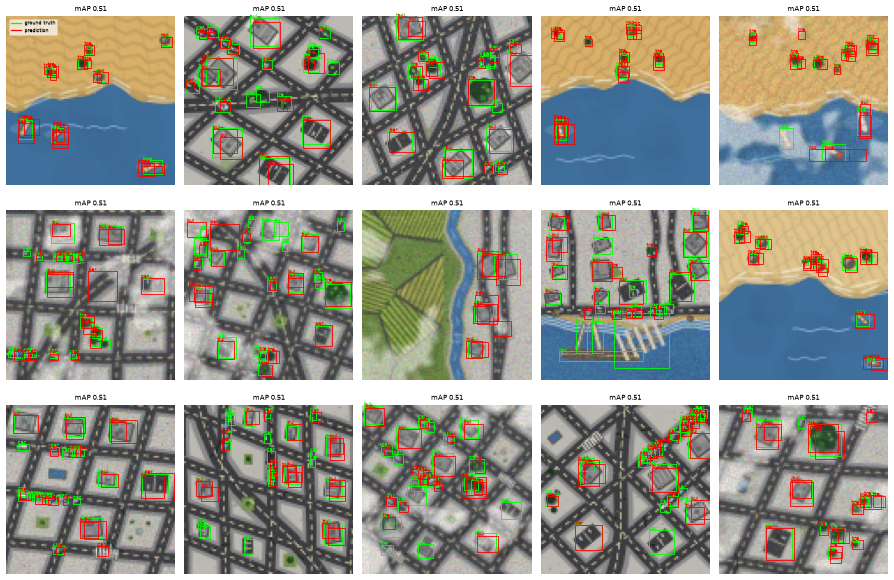

In [11]:
model.eval()
with torch.no_grad():
    predictions = model(val_images_device).cpu()
detections = decode_predictions(predictions, ANCHORS)
mean_ap, per_class_ap = mean_average_precision(detections, ground_truths)
test_predictions = model(test_images.to(DEVICE)).cpu()   # held-out test set
test_detections = decode_predictions(test_predictions, ANCHORS)
test_mean_ap, _ = mean_average_precision(test_detections, test_ground_truths)
print(f"validation mAP@0.5 = {mean_ap:.3f}")
print(f"test       mAP@0.5 = {test_mean_ap:.3f}   <- reported once, never used for tuning")
print("per-class AP@0.5:")
for class_name in CLASSES:
    value = per_class_ap[class_name]
    print(f"  {class_name:11s} {'-' if value is None else f'{value:.3f}'}")

# Reference points for mAP@0.5: an empty prediction set scores 0 (lower bound),
# a perfect oracle 1. Every point between is earned by the detector.
print("no-object baseline      mAP@0.5 = 0.000")

# Per-class precision-recall curves: AP is the area under each curve and
# mAP@0.5 is their mean over the classes present, so a rare class's noisy AP
# counts as much as a common one.
fig, ax = plt.subplots(figsize=(6.2, 4.8), dpi=80)
for class_name in CLASSES:
    recall_curve, precision_curve, ap = precision_recall_curve(detections, ground_truths, class_name)
    if recall_curve is None:
        continue
    ax.plot(recall_curve, precision_curve, label=f"{class_name} (AP {ap:.2f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("per-class precision-recall @ IoU 0.5")
ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

# Training curves: the training loss falls while validation mAP@0.5 rises,
# then both flatten. The best checkpoint is the peak of the mAP curve.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), dpi=80)
epochs = [row[0] for row in history]
axes[0].plot(epochs, [row[1] for row in history], label="train")
axes[0].plot(epochs, [row[2] for row in history], label="validation")
axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, [row[2] for row in history])
axes[1].set_title("validation loss"); axes[1].set_xlabel("epoch")
best_epoch = epochs[int(np.argmax([row[3] for row in history]))]
axes[2].plot(epochs, [row[3] for row in history])
axes[2].axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
axes[2].set_title(f"validation mAP@0.5 (best {max(row[3] for row in history):.2f} @ epoch {best_epoch})")
axes[2].set_xlabel("epoch")
plt.tight_layout()
plt.show()


def draw_boxes(ax, boxes, color):
    """Draw (class, score, x0, y0, x1, y1) boxes on a scene axis."""
    for class_name, score, x0, y0, x1, y1 in boxes:
        ax.add_patch(plt.Rectangle(
            (x0 * SIZE, (1 - y1) * SIZE), (x1 - x0) * SIZE, (y1 - y0) * SIZE,
            edgecolor=color, facecolor="none", linewidth=1.0))
        ax.text(x0 * SIZE, (1 - y1) * SIZE, class_name[:3], color=color, fontsize=6)


# Qualitative check: three rows of five validation scenes, ground truth (green)
# against the best-checkpoint predictions (red).
fig, axes = plt.subplots(3, 5, figsize=(15, 10), dpi=60)
for sample_idx, ax in enumerate(axes.ravel()):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    draw_boxes(ax, [(n, 1.0, *b) for n, b in ground_truths[sample_idx]], "lime")
    draw_boxes(ax, detections[sample_idx], "red")
    ax.set_title(f"mAP {mean_ap:.2f}", fontsize=8)
    ax.axis("off")
legend_handles = [plt.Line2D([], [], color="lime", label="ground truth"),
                  plt.Line2D([], [], color="red", label="prediction")]
axes.ravel()[0].legend(handles=legend_handles, loc="upper left", fontsize=6, framealpha=0.7)
plt.tight_layout()
plt.show()


**Figure read-out.** Per-class precision-recall curves (AP per class), then train/validation loss and validation mAP, then validation scenes with ground truth (green) and predictions (red). Test mAP is ~0.47; `car` (~4 px) is the weakest class.

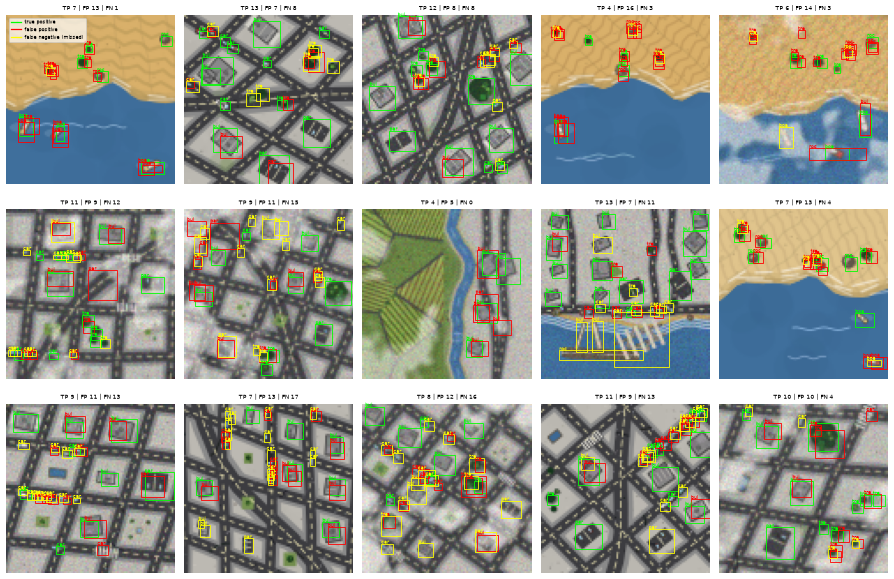

In [12]:
def match_detections(detections, targets, iou_threshold=0.5):
    """Greedy per-image matching; return (true positives, false positives, misses)."""
    true_positives, false_positives, false_negatives = [], [], []
    for image_idx in range(len(detections)):
        matched = [False] * len(targets[image_idx])
        image_tp, image_fp = [], []
        for detection in sorted(detections[image_idx], key=lambda det: -det[1]):
            class_name, score, *box = detection
            best_iou, best_idx = -1.0, -1
            for box_idx, (target_name, target_box) in enumerate(targets[image_idx]):
                if target_name == class_name and not matched[box_idx]:
                    iou = box_iou(box, target_box)
                    if iou > best_iou:
                        best_iou, best_idx = iou, box_idx
            if best_iou >= iou_threshold:
                matched[best_idx] = True
                image_tp.append(detection)
            else:
                image_fp.append(detection)
        image_fn = [targets[image_idx][i] for i in range(len(matched)) if not matched[i]]
        true_positives.append(image_tp)
        false_positives.append(image_fp)
        false_negatives.append(image_fn)
    return true_positives, false_positives, false_negatives


true_positives, false_positives, false_negatives = match_detections(detections, ground_truths)

# Failure gallery: matched detections (green), false positives (red) and missed
# ground-truth objects (yellow) over fifteen validation scenes.
fig, axes = plt.subplots(3, 5, figsize=(15, 10), dpi=60)
for sample_idx, ax in enumerate(axes.ravel()):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    draw_boxes(ax, true_positives[sample_idx], "lime")
    draw_boxes(ax, false_positives[sample_idx], "red")
    draw_boxes(ax, [(name, 1.0, *box) for name, box in false_negatives[sample_idx]], "yellow")
    ax.set_title(
        f"TP {len(true_positives[sample_idx])} | FP {len(false_positives[sample_idx])}"
        f" | FN {len(false_negatives[sample_idx])}",
        fontsize=7,
    )
    ax.axis("off")
legend_handles = [plt.Line2D([], [], color="lime", label="true positive"),
                  plt.Line2D([], [], color="red", label="false positive"),
                  plt.Line2D([], [], color="yellow", label="false negative (missed)")]
axes.ravel()[0].legend(handles=legend_handles, loc="upper left", fontsize=6, framealpha=0.7)
plt.tight_layout()
plt.show()


**Figure read-out.** Failure gallery: true positives (green), false positives (red) and missed objects (yellow). Errors cluster on dense cars/trees and partly clouded scenes.

### How the detection metric behaves

**mAP@0.5 vs higher IoU.** A detection counts as correct at IoU >= 0.5, which
is lenient: a box can be off by half its size and still pass. Re-scoring at
IoU 0.65 and 0.75 measures how *tight* the boxes are, and the gap is the
localisation error the headline number hides.

**Score threshold.** `decode_predictions` uses a deliberately permissive score
threshold, so lowering or raising it trades precision against recall and the
number of reported objects. This is the detector's **operating point**.

mAP@0.50 = 0.515
mAP@0.65 = 0.196
mAP@0.75 = 0.066


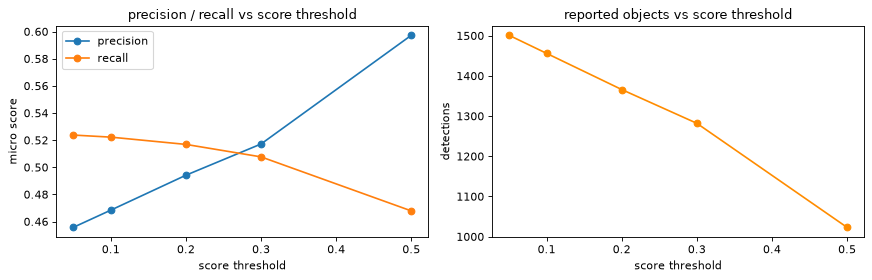

In [13]:
# mAP at stricter IoU thresholds: @0.5 flatters loose boxes.
for iou_threshold in (0.5, 0.65, 0.75):
    aps = [average_precision(detections, ground_truths, name, iou_threshold=iou_threshold)
           for name in CLASSES]
    present = [value for value in aps if value is not None]
    print(f"mAP@{iou_threshold:.2f} = {np.mean(present):.3f}")


def operating_point(detections_split):
    """Micro precision / recall / object count at one operating point."""
    tp = fp = fn = 0
    for image_idx in range(len(detections_split)):
        image_tp, image_fp, image_fn = match_detections(
            [detections_split[image_idx]], [ground_truths[image_idx]])
        tp += len(image_tp[0]); fp += len(image_fp[0]); fn += len(image_fn[0])
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return precision, recall, tp + fp


# Score-threshold sweep: precision, recall and the number of detections.
score_thresholds = [0.05, 0.1, 0.2, 0.3, 0.5]
sweep_precision, sweep_recall, sweep_count = [], [], []
for score_threshold in score_thresholds:
    sweep_detections = decode_predictions(predictions, ANCHORS, score_threshold=score_threshold)
    precision, recall, count = operating_point(sweep_detections)
    sweep_precision.append(precision); sweep_recall.append(recall); sweep_count.append(count)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=80)
axes[0].plot(score_thresholds, sweep_precision, marker="o", label="precision")
axes[0].plot(score_thresholds, sweep_recall, marker="o", label="recall")
axes[0].set_xlabel("score threshold"); axes[0].set_ylabel("micro score")
axes[0].set_title("precision / recall vs score threshold"); axes[0].legend()
axes[1].plot(score_thresholds, sweep_count, marker="o", color="darkorange")
axes[1].set_xlabel("score threshold"); axes[1].set_ylabel("detections")
axes[1].set_title("reported objects vs score threshold")
plt.tight_layout()
plt.show()


**Figure read-out.** mAP at IoU 0.5 / 0.65 / 0.75 and the score-threshold sweep: @0.5 flatters loose boxes, and the threshold trades precision against recall and the reported count.

### Evaluation protocol

Three disjoint splits: **train** (fit), **validation** (checkpoint selection) and
**test** (reported once, never used for any decision). The detection and
instance metrics below are printed for validation and test; the failure
gallery uses validation only, to keep the test set untouched.


## Instance segmentation: a mask per anchor on the detector

**Use case.** In aerial forests the crowns of neighbouring trees overlap, so a
single "tree" class cannot tell how many trees there are. We extend the anchor
detector above into a **multi-head** model that predicts an **instance mask per
anchor**:

- **objectness head** and **box head** — as in the detection section;
- **mask head per anchor** — for every `(cell, anchor)`, a small
  `MASK_SIZE x MASK_SIZE` mask, upscaled to the predicted box at inference.

**Training target:** the GT instance mask **cropped to its box** and resized to
`MASK_SIZE` (a Mask R-CNN-style, box-relative mask). The forests are generated
with exact instance masks, from sparse stands (a handful of trees) to dense
canopy (dozens of overlapping crowns), plus an **urban avenue** layout (regular
rows of street trees lining a road) and scattered **boulders** under the canopy
that the model must not count as trees.

**Metrics:** count MAE, per-instance IoU and detection rate, plus the
**training and validation loss curves** (plus count error and IoU vs epoch) and a **mean-count
baseline** that always predicts the average training count without looking at
the image.


In [14]:
FOREST_SIZE = 64
FOREST_GRID = 16

from matplotlib.path import Path

from mlpsyn.materials import MATERIALS


def make_forest_data(n_samples, size=FOREST_SIZE, seed=0):
    """Synthetic forests with exact instance masks, from sparse stands to dense canopy.

    Four layouts vary tree count, spacing and order: **sparse / medium / dense**
    random stands and a regular **avenue** of street trees. Scattered **boulders**
    lie under the canopy but are not instances. The background material is soil,
    grass or foliage; a few trees get an autumn/brown tint. Dense forests are
    heavily overlapping, which is the hard, realistic case for instance masks.
    """
    rng = np.random.default_rng(seed)
    images, instances = [], []
    grid_y, grid_x = np.mgrid[0:1:size * 1j, 0:1:size * 1j]
    points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    # regime -> (min trees, max trees, min trunk distance, canopy radius range)
    # Zoomed out: smaller crowns and more of them, with a wide density range.
    regimes = {
        "sparse": (7, 12, 0.17, (0.05, 0.08)),
        "medium": (14, 22, 0.11, (0.045, 0.075)),
        "dense": (20, 32, 0.075, (0.035, 0.065)),
        "avenue": (8, 14, 0.09, (0.04, 0.06)),
    }
    for _ in range(n_samples):
        regime = str(rng.choice(
            ["sparse", "medium", "dense", "avenue"], p=[0.3, 0.3, 0.2, 0.2]))
        low, high, min_dist, radius_range = regimes[regime]
        background_key = str(rng.choice(["soil", "grass", "foliage"]))
        image = MATERIALS[background_key](size=size, seed=int(rng.integers(1_000_000)))
        image = image.astype(np.float32) / 255.0
        instance = np.zeros((size, size), np.int32)
        # Scattered boulders, drawn before the trees so crowns overlap them.
        # They lie under the canopy and are NOT instances: the model must not
        # count a grey rock as a tree crown.
        n_boulders = int(rng.integers(1, 4)) if regime == "sparse" else (
            int(rng.integers(0, 3)) if regime == "medium" else 0)
        for _ in range(n_boulders):
            bx, by = rng.uniform(0.08, 0.92, size=2)
            brad = rng.uniform(0.018, 0.035)
            angles = np.linspace(0, 2 * np.pi, 10, endpoint=False)
            radii = brad * (1 + 0.35 * rng.normal(size=len(angles)))
            poly = np.column_stack([
                bx + radii * np.cos(angles), by + radii * np.sin(angles)])
            inside = Path(poly).contains_points(points).reshape(size, size)
            shade = float(rng.uniform(0.42, 0.6))
            rock = np.array([shade, shade, shade * 0.95])
            image[inside] = rock
            lift = ((grid_x - (bx - brad * 0.3)) ** 2
                    + (grid_y - (by - brad * 0.3)) ** 2) < (brad * 0.4) ** 2
            image[lift & inside] = np.clip(rock + 0.14, 0, 1)
        # Keep trunks separated so instances stay distinguishable, but let crowns overlap.
        centres = []
        if regime == "avenue":
            # Urban avenue: near-regular rows either side of a street, the
            # order/discipline test for the instance model. A road stripe and
            # dashed centre line make the setting explicit.
            image[int(0.44 * size):int(0.56 * size)] = np.array([0.30, 0.30, 0.31])
            step_x = max(3, size // 24)
            for x in range(0, size, step_x * 3):
                image[int(0.494 * size):int(0.506 * size), x:x + step_x] = 0.78
            for row_y in (0.27, 0.73):
                for k in range(int(rng.integers(4, 7))):
                    centres.append(np.array([
                        0.12 + k * 0.15 + rng.uniform(-0.02, 0.02),
                        row_y + rng.uniform(-0.025, 0.025)]))
        else:
            for _ in range(int(rng.integers(low, high + 1))):
                for _try in range(40):
                    candidate = rng.uniform(0.06, 0.94, size=2)
                    if all(np.hypot(*(candidate - centre)) >= min_dist for centre in centres):
                        centres.append(candidate)
                        break
        for instance_id, centre in enumerate(centres, start=1):
            radius = rng.uniform(*radius_range)
            angles = np.linspace(0, 2 * np.pi, 14, endpoint=False)
            radii = radius * (1 + 0.22 * rng.normal(size=len(angles)))
            polygon = np.column_stack([
                centre[0] + radii * np.cos(angles), centre[1] + radii * np.sin(angles)])
            inside = Path(polygon).contains_points(points).reshape(size, size)
            green = np.clip(np.array([0.15, 0.45, 0.16]) + rng.uniform(-0.05, 0.05, 3), 0, 1)
            if rng.random() < 0.15:  # occasional autumn / brown tree
                green = np.clip(green * np.array([1.35, 0.8, 0.55]), 0, 1)
            image[inside] = green
            for _ in range(3):  # lighter foliage highlights
                highlight = centre + rng.uniform(-radius, radius, 2) * 0.5
                disc = ((grid_x - highlight[0]) ** 2 + (grid_y - highlight[1]) ** 2) < (radius * 0.3) ** 2
                image[disc & inside] = np.clip(green + 0.12, 0, 1)
            instance[inside] = instance_id  # later crown wins on overlap
        # Relabel so ids are contiguous over *visible* crowns: a tree fully hidden
        # by later crowns is dropped from the count and the instance masks.
        visible = [i for i in range(1, len(centres) + 1) if np.any(instance == i)]
        if len(visible) != len(centres):
            remapped = np.zeros_like(instance)
            for new_id, old_id in enumerate(visible, start=1):
                remapped[instance == old_id] = new_id
            instance = remapped
        # A little optical blur + detector noise, so the masks must be robust too.
        frame = (image * 255).astype(np.uint8)
        frame = apply_sensor(
            frame, rng, kind="poisson" if rng.random() < 0.5 else "gaussian",
            blur_radius=rng.uniform(0.2, 0.8),
        )
        images.append(frame)
        instances.append(instance)
    return np.stack(images), instances


started = time.time()
forest_images, forest_instances = make_forest_data(400)
print("forest data", forest_images.shape, "in", round(time.time() - started, 1), "s")


forest data (400, 64, 64, 3) in 3.6 s


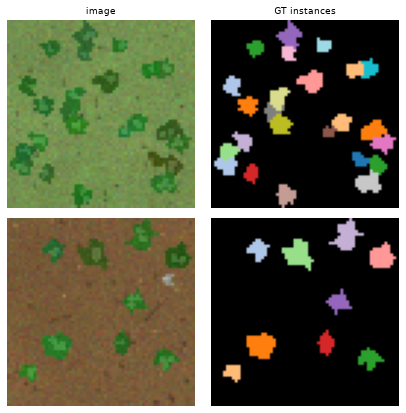

In [15]:
def colorize_instances(instance_map):
    """Map integer instance ids to a repeating qualitative colormap."""
    color_map = plt.get_cmap("tab20")
    rgb = np.zeros((*instance_map.shape, 3))
    for instance_id in range(1, int(instance_map.max()) + 1):
        rgb[instance_map == instance_id] = color_map(instance_id % 20)[:3]
    return rgb


fig, axes = plt.subplots(2, 2, figsize=(6, 6), dpi=70)
for sample_idx in range(2):
    axes[sample_idx, 0].imshow(forest_images[sample_idx])
    axes[sample_idx, 1].imshow(colorize_instances(forest_instances[sample_idx]))
for ax, title in zip(axes[0], ["image", "GT instances"]):
    ax.set_title(title, fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()


In [16]:
N_FOREST_ANCHORS = 3


def tree_box(instance_map, instance_id):
    """Normalised (x0, y0, x1, y1) box of one tree instance."""
    rows, cols = np.nonzero(instance_map == instance_id)
    return (cols.min() / FOREST_SIZE, 1 - (rows.max() + 1) / FOREST_SIZE,
            (cols.max() + 1) / FOREST_SIZE, 1 - rows.min() / FOREST_SIZE)


forest_boxes = []
for instance_map in forest_instances:
    for instance_id in range(1, int(instance_map.max()) + 1):
        x0, y0, x1, y1 = tree_box(instance_map, instance_id)
        forest_boxes.append((x1 - x0, y1 - y0))
FOREST_ANCHORS = kmeans_anchors(forest_boxes, N_FOREST_ANCHORS, log_space=False)
print("tree anchors (width, height):", np.round(FOREST_ANCHORS, 3).tolist())


def forest_targets(instance_map, anchors):
    """Encode tree instances into (objectness, box, instance-id) targets."""
    objectness = np.zeros((FOREST_GRID, FOREST_GRID, len(anchors)), np.float32)
    box_target = np.zeros((FOREST_GRID, FOREST_GRID, len(anchors), 4), np.float32)
    instance_id = -np.ones((FOREST_GRID, FOREST_GRID, len(anchors)), np.int32)
    for current_id in range(1, int(instance_map.max()) + 1):
        x0, y0, x1, y1 = tree_box(instance_map, current_id)
        width, height = x1 - x0, y1 - y0
        center_x, center_y = (x0 + x1) / 2, (y0 + y1) / 2
        anchor_idx = int(np.argmax([shape_iou((width, height), anchor) for anchor in anchors]))
        col = int(np.clip(center_x * FOREST_GRID, 0, FOREST_GRID - 1))
        row = int(np.clip((1 - center_y) * FOREST_GRID, 0, FOREST_GRID - 1))
        objectness[row, col, anchor_idx] = 1
        instance_id[row, col, anchor_idx] = current_id
        box_target[row, col, anchor_idx] = [
            center_x * FOREST_GRID - col, (1 - center_y) * FOREST_GRID - row,
            np.log(width / anchors[anchor_idx][0]), np.log(height / anchors[anchor_idx][1])]
    return objectness, box_target, instance_id


forest_objectness, forest_box_target, forest_ids = [], [], []
for instance_map in forest_instances:
    obj, box, ids = forest_targets(instance_map, FOREST_ANCHORS)
    forest_objectness.append(obj); forest_box_target.append(box); forest_ids.append(ids)
forest_objectness = torch.from_numpy(np.stack(forest_objectness))
forest_box_target = torch.from_numpy(np.stack(forest_box_target))
forest_ids = torch.from_numpy(np.stack(forest_ids))


def forest_instance_scores(ground_truth, predicted):
    """Best IoU of each GT instance with any predicted instance."""
    n_gt, n_pred = int(ground_truth.max()), int(predicted.max())
    if n_gt == 0:
        return [], 0
    joint = (predicted.astype(np.int64) * (n_gt + 1) + ground_truth).ravel()
    intersection = np.bincount(
        joint, minlength=(n_pred + 1) * (n_gt + 1)).reshape(n_pred + 1, n_gt + 1)
    area_pred = np.bincount(predicted.ravel(), minlength=n_pred + 1)
    area_gt = np.bincount(ground_truth.ravel(), minlength=n_gt + 1)
    intersections, matched = [], 0
    for gt_id in range(1, n_gt + 1):
        best = 0.0
        for pred_id in range(1, n_pred + 1):
            union = area_pred[pred_id] + area_gt[gt_id] - intersection[pred_id, gt_id]
            if union:
                best = max(best, intersection[pred_id, gt_id] / union)
        intersections.append(best)
        matched += best >= 0.5
    return intersections, matched


tree anchors (width, height): [[0.091, 0.092], [0.121, 0.12], [0.153, 0.153]]


In [17]:
MASK_SIZE = 24  # per-anchor mask resolution (finer = less fragmented masks)


class AnchorMaskDetector(nn.Module):
    """Multi-head anchor detector whose mask head predicts one mask per anchor."""

    def __init__(self, n_anchors, mask_size=MASK_SIZE, base=32):
        super().__init__()
        self.n_anchors = n_anchors
        self.mask_size = mask_size

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))

        self.backbone = nn.Sequential(block(3, base, 2), block(base, base * 2, 2))
        self.objectness_head = nn.Conv2d(base * 2, n_anchors, 1)
        self.box_head = nn.Conv2d(base * 2, n_anchors * 4, 1)
        # One small mask per (cell, anchor): A * mask_size * mask_size channels.
        self.mask_conv = nn.Conv2d(base * 2, base * 2, 3, 1, 1)
        self.mask_head = nn.Conv2d(base * 2, n_anchors * mask_size * mask_size, 1)

    def forward(self, image_batch):
        features = self.backbone(image_batch)
        n = len(image_batch)
        objectness = self.objectness_head(features).permute(0, 2, 3, 1)
        box = self.box_head(features).view(
            n, self.n_anchors, 4, FOREST_GRID, FOREST_GRID).permute(0, 3, 4, 1, 2)
        mask = self.mask_head(F.relu(self.mask_conv(features))).view(
            n, self.n_anchors, self.mask_size, self.mask_size, FOREST_GRID, FOREST_GRID)
        return objectness, box, mask


def forest_nms(candidates, iou_threshold=0.5):
    """Greedy NMS over (score, box, payload) detections."""
    candidates = sorted(candidates, key=lambda candidate: -candidate[0])
    kept = []
    for candidate in candidates:
        if all(box_iou(candidate[1], other[1]) <= iou_threshold for other in kept):
            kept.append(candidate)
    return kept


def decode_anchor(objectness, box_pred, mask, anchors,
                  score_threshold=0.5, iou_threshold=0.4, top_k=45):
    """Decode per-anchor-mask outputs into (score, box, mask_block) detections."""
    objectness = torch.sigmoid(objectness)
    center_x = torch.sigmoid(box_pred[..., 0]); center_y = torch.sigmoid(box_pred[..., 1])
    width = box_pred[..., 2]; height = box_pred[..., 3]
    results = []
    for image_idx in range(len(objectness)):
        candidates = []
        for anchor_idx, (anchor_w, anchor_h) in enumerate(anchors):
            for row in range(FOREST_GRID):
                for col in range(FOREST_GRID):
                    score = float(objectness[image_idx, row, col, anchor_idx])
                    if score < score_threshold:
                        continue
                    cx = (col + float(center_x[image_idx, row, col, anchor_idx])) / FOREST_GRID
                    cy = 1 - (row + float(center_y[image_idx, row, col, anchor_idx])) / FOREST_GRID
                    w = anchor_w * float(torch.exp(width[image_idx, row, col, anchor_idx]))
                    h = anchor_h * float(torch.exp(height[image_idx, row, col, anchor_idx]))
                    box = (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)
                    mask_block = mask[image_idx, anchor_idx, :, :, row, col].cpu()
                    candidates.append((score, box, mask_block))
        results.append(forest_nms(candidates, iou_threshold)[:top_k])
    return results


def crop_resize(mask_array, out_size):
    """Crop a binary mask to its bbox and resize to out_size x out_size."""
    rows, cols = np.nonzero(mask_array)
    crop = mask_array[rows.min():rows.max() + 1, cols.min():cols.max() + 1].astype(np.float32)
    tensor = torch.from_numpy(crop)[None, None]
    return F.interpolate(tensor, size=(out_size, out_size), mode="bilinear",
                         align_corners=False)[0, 0].numpy()


def per_anchor_map(detections):
    """Resize each detection's mask block to its box and paint instances."""
    labels = np.zeros((FOREST_SIZE, FOREST_SIZE), np.int32)
    grid_y, grid_x = np.mgrid[0:FOREST_SIZE, 0:FOREST_SIZE]
    for instance_id, (score, box, mask_block) in enumerate(detections, start=1):
        x0, y0, x1, y1 = box
        px0 = max(int(round(x0 * FOREST_SIZE)), 0); px1 = min(int(round(x1 * FOREST_SIZE)), FOREST_SIZE)
        py0 = max(int(round((1 - y1) * FOREST_SIZE)), 0); py1 = min(int(round((1 - y0) * FOREST_SIZE)), FOREST_SIZE)
        if px1 <= px0 or py1 <= py0:
            continue
        upsampled = torch.sigmoid(F.interpolate(
            mask_block[None, None], size=(py1 - py0, px1 - px0),
            mode="bilinear", align_corners=False))[0, 0].numpy()
        full = np.zeros((FOREST_SIZE, FOREST_SIZE), np.float32)
        full[py0:py1, px0:px1] = upsampled
        in_box = ((grid_x >= x0 * FOREST_SIZE) & (grid_x <= x1 * FOREST_SIZE)
                  & (grid_y >= (1 - y1) * FOREST_SIZE) & (grid_y <= (1 - y0) * FOREST_SIZE))
        labels[(full > 0.5) & in_box & (labels == 0)] = instance_id
    return labels


forest_model = AnchorMaskDetector(N_FOREST_ANCHORS).to(DEVICE)
n_parameters = sum(p.numel() for p in forest_model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


216.0 k parameters


### What the mask head actually learns (visual)

The mask target is **box-relative** (Mask R-CNN style): the GT instance mask is
**cropped to its bounding box and resized** to `MASK_SIZE x MASK_SIZE`. The head
therefore never sees absolute position — only the shape of the object inside
its own box. The figure shows one forest tree: the image, the instance map, the
chosen instance with its box, and the small target the head is trained on.

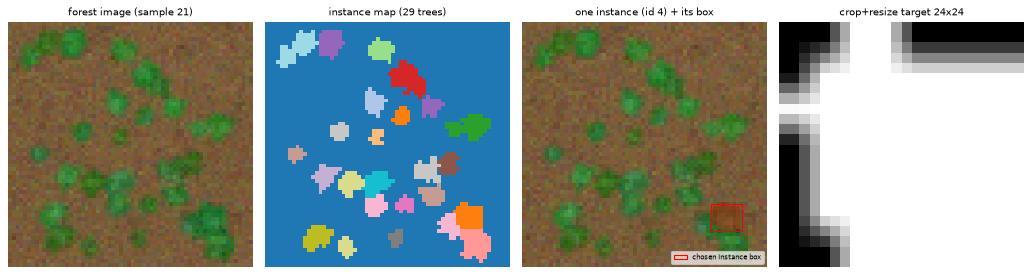

In [18]:
import matplotlib.patches as mpatches
# Pick a validation forest with several trees and inspect one instance.
sample_index = int(np.argmax([int(inst.max()) for inst in forest_instances[:80]]))
image = forest_images[sample_index]
instance_map = forest_instances[sample_index]
# Use the largest fully-visible instance (not clipped at the border) so both
# the box and the cropped target are easy to read.
areas = np.bincount(instance_map.ravel()); areas[0] = 0
candidates = []
for candidate_id in np.nonzero(areas)[0]:
    candidate_rows, candidate_cols = np.nonzero(instance_map == candidate_id)
    if candidate_rows.min() > 2 and candidate_cols.min() > 2 and \
       candidate_rows.max() < FOREST_SIZE - 3 and candidate_cols.max() < FOREST_SIZE - 3:
        candidates.append((int(areas[candidate_id]), int(candidate_id)))
instance_id = max(candidates)[1] if candidates else int(np.argmax(areas))
instance_mask = instance_map == instance_id
rows, cols = np.nonzero(instance_mask)
bbox = (cols.min(), rows.min(), cols.max() + 1, rows.max() + 1)
mask_target = crop_resize(instance_mask, MASK_SIZE)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), dpi=80)
axes[0].imshow(image); axes[0].set_title(f"forest image (sample {sample_index})", fontsize=9)
axes[1].imshow(instance_map, cmap="tab20"); axes[1].set_title(
    f"instance map ({int(instance_map.max())} trees)", fontsize=9)
axes[2].imshow(image)
axes[2].add_patch(mpatches.Rectangle((bbox[0], bbox[1]), bbox[2] - bbox[0], bbox[3] - bbox[1],
                 edgecolor="red", facecolor="none", linewidth=1.0))
axes[2].imshow(np.where(instance_mask, 1.0, np.nan), cmap="autumn", alpha=0.4)
axes[2].set_title(f"one instance (id {instance_id}) + its box", fontsize=9)
axes[3].imshow(mask_target, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[3].set_title(f"crop+resize target {MASK_SIZE}x{MASK_SIZE}", fontsize=9)
axes[2].legend(handles=[mpatches.Patch(facecolor="none", edgecolor="red", label="chosen instance box")],
               loc="lower right", fontsize=6, framealpha=0.7)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


**Figure read-out.** One forest instance: image, instance map, the chosen instance (red box) and the crop+resize mask target the head learns - a box-relative mask.

In [19]:
forest_images_device = torch.from_numpy(
    forest_images.astype(np.float32).transpose(0, 3, 1, 2) / 255.0)
n_forest_val, n_forest_test = 56, 44
cut = n_forest_val + n_forest_test
train_images = forest_images_device[:-cut]
train_objectness = forest_objectness[:-cut]
train_box_target = forest_box_target[:-cut]
train_instances = forest_instances[:-cut]
val_images_device = forest_images_device[-cut:-n_forest_test]
val_objectness = forest_objectness[-cut:-n_forest_test]
val_box_target = forest_box_target[-cut:-n_forest_test]
val_ids = forest_ids[-cut:-n_forest_test]
val_instances = forest_instances[-cut:-n_forest_test]
test_images_device = forest_images_device[-n_forest_test:]
test_instances = forest_instances[-n_forest_test:]


def flip_forest_batch(images, objectness, box_target, ids, instance_maps, rng):
    """Random flips; keep images, targets, instance ids and masks consistent."""
    if rng.random() < 0.5:  # horizontal
        images = torch.flip(images, [3])
        objectness = torch.flip(objectness, [2]).clone()
        box_target = torch.flip(box_target, [2]).clone()
        box_target[..., 0] = 1 - box_target[..., 0]
        ids = torch.flip(ids, [2]).clone()
        instance_maps = [np.flip(instance_map, axis=1).copy() for instance_map in instance_maps]
    if rng.random() < 0.5:  # vertical
        images = torch.flip(images, [2])
        objectness = torch.flip(objectness, [1]).clone()
        box_target = torch.flip(box_target, [1]).clone()
        box_target[..., 1] = 1 - box_target[..., 1]
        ids = torch.flip(ids, [1]).clone()
        instance_maps = [np.flip(instance_map, axis=0).copy() for instance_map in instance_maps]
    return images, objectness, box_target, ids, instance_maps


def forest_split_loss(images, objectness_target, box_target, ids, instance_maps):
    """Total instance-model loss on a split (matches the training objective)."""
    out_objectness, out_box, out_mask = forest_model(images)
    positive = objectness_target > 0.5
    objectness_loss = F.binary_cross_entropy_with_logits(
        out_objectness, objectness_target, pos_weight=torch.tensor(10.0, device=DEVICE))
    box_loss = F.smooth_l1_loss(out_box[positive], box_target[positive])
    batch_index, row_index, col_index, anchor_index = positive.nonzero(as_tuple=True)
    selected_masks = out_mask[batch_index, anchor_index, :, :, row_index, col_index]
    positive_cpu = positive.cpu()
    instance_ids = ids[positive_cpu].tolist()
    image_in_batch = positive_cpu.nonzero(as_tuple=True)[0].tolist()
    mask_target = torch.from_numpy(np.stack([
        crop_resize(instance_maps[image_in_batch[k]] == instance_ids[k], MASK_SIZE)
        for k in range(len(instance_ids))])).to(DEVICE)
    probability = torch.sigmoid(selected_masks)
    intersection = (probability * mask_target).sum((1, 2))
    union = probability.sum((1, 2)) + mask_target.sum((1, 2))
    dice = (1 - (2 * intersection + 1) / (union + 1)).mean()
    mask_bce = F.binary_cross_entropy_with_logits(
        selected_masks, mask_target, pos_weight=torch.tensor(3.0, device=DEVICE))
    return objectness_loss + 2 * box_loss + 4 * (mask_bce + dice)


optimizer = torch.optim.AdamW(forest_model.parameters(), lr=2e-3)
EPOCHS, BATCH_SIZE = 70, 16
rng = np.random.default_rng(0)
best_iou, best_state = -1.0, None
history = []
started = time.time()
for epoch in range(EPOCHS):
    forest_model.train()
    permutation = torch.randperm(len(train_images), device="cpu")
    running_loss = 0.0
    for start in range(0, len(train_images), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        batch_images, batch_objectness, batch_box, batch_ids, batch_instances = flip_forest_batch(
            train_images[batch_indices], train_objectness[batch_indices],
            train_box_target[batch_indices], forest_ids[batch_indices],
            [train_instances[index] for index in batch_indices.tolist()], rng)
        batch_images = batch_images.to(DEVICE)
        batch_objectness = batch_objectness.to(DEVICE)
        batch_box = batch_box.to(DEVICE)
        optimizer.zero_grad()
        # Each positive predicts a small mask; the target is the GT instance mask
        # cropped to its box, so the mask lives in the box frame (Mask R-CNN style).
        objectness, box_prediction, mask = forest_model(batch_images)
        positive = batch_objectness > 0.5
        objectness_loss = F.binary_cross_entropy_with_logits(
            objectness, batch_objectness, pos_weight=torch.tensor(10.0, device=DEVICE))
        box_loss = F.smooth_l1_loss(box_prediction[positive], batch_box[positive])
        # Gather the predicted mask block of every positive and its box-relative GT.
        batch_index, row_index, col_index, anchor_index = positive.nonzero(as_tuple=True)
        selected_masks = mask[batch_index, anchor_index, :, :, row_index, col_index]
        positive_cpu = positive.cpu()
        instance_ids = batch_ids[positive_cpu].tolist()
        image_in_batch = positive_cpu.nonzero(as_tuple=True)[0].tolist()
        mask_target = torch.from_numpy(np.stack([
            crop_resize(batch_instances[image_in_batch[k]] == instance_ids[k], MASK_SIZE)
            for k in range(len(instance_ids))])).to(DEVICE)
        probability = torch.sigmoid(selected_masks)
        intersection = (probability * mask_target).sum((1, 2))
        union = probability.sum((1, 2)) + mask_target.sum((1, 2))
        dice = (1 - (2 * intersection + 1) / (union + 1)).mean()
        mask_bce = F.binary_cross_entropy_with_logits(
            selected_masks, mask_target, pos_weight=torch.tensor(3.0, device=DEVICE))
        loss = objectness_loss + 2 * box_loss + 4 * (mask_bce + dice)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 10 == 9 or epoch == EPOCHS - 1:
        forest_model.eval()
        with torch.no_grad():
            validation_loss = float(forest_split_loss(
                val_images_device.to(DEVICE), val_objectness.to(DEVICE),
                val_box_target.to(DEVICE), val_ids, val_instances).item())
            objectness, box_prediction, mask = forest_model(val_images_device.to(DEVICE))
        detections = decode_anchor(objectness.cpu(), box_prediction.cpu(),
                                   mask.cpu(), FOREST_ANCHORS)
        count_errors, count_mape, intersections, matched, total = [], [], [], 0, 0
        for sample_idx in range(n_forest_val):
            labels = per_anchor_map(detections[sample_idx])
            ground_truth = val_instances[sample_idx]
            gt_count = max(int(ground_truth.max()), 1)
            predicted_count = len(detections[sample_idx])
            count_errors.append(abs(predicted_count - gt_count))
            count_mape.append(abs(predicted_count - gt_count) / gt_count)
            total += gt_count
            sample_ious, sample_matched = forest_instance_scores(ground_truth, labels)
            intersections += sample_ious; matched += sample_matched
        mean_iou = float(np.mean(intersections))
        if mean_iou > best_iou:
            best_iou = mean_iou
            best_state = copy.deepcopy(forest_model.state_dict())
        history.append((epoch, running_loss / len(train_images), validation_loss,
                        float(np.mean(count_errors)), mean_iou, matched / total))
        print(
            f"epoch {epoch:3d} | loss {running_loss/len(train_images):.3f}"
            f" | val loss {validation_loss:.3f}"
            f" | count MAE {np.mean(count_errors):.2f} | MAPE {100*np.mean(count_mape):.0f}%"
            f" | inst IoU {mean_iou:.3f}"
            f" | best {best_iou:.3f} | detect {matched}/{total} | {time.time()-started:.0f}s"
        )
forest_model.load_state_dict(best_state)
train_time = time.time() - started
print(f"best instance IoU {best_iou:.3f} | training time {train_time:.1f} s")


epoch   9 | loss 3.612 | val loss 3.639 | count MAE 3.82 | MAPE 25% | inst IoU 0.536 | best 0.536 | detect 581/915 | 7s


epoch  19 | loss 3.282 | val loss 3.348 | count MAE 5.25 | MAPE 32% | inst IoU 0.542 | best 0.542 | detect 568/915 | 13s


epoch  29 | loss 3.054 | val loss 3.185 | count MAE 3.96 | MAPE 24% | inst IoU 0.546 | best 0.546 | detect 570/915 | 19s


epoch  39 | loss 2.906 | val loss 3.107 | count MAE 3.66 | MAPE 23% | inst IoU 0.541 | best 0.546 | detect 563/915 | 25s


epoch  49 | loss 2.795 | val loss 3.082 | count MAE 3.09 | MAPE 19% | inst IoU 0.555 | best 0.555 | detect 620/915 | 31s


epoch  59 | loss 2.691 | val loss 3.080 | count MAE 3.95 | MAPE 24% | inst IoU 0.546 | best 0.555 | detect 574/915 | 37s


epoch  69 | loss 2.653 | val loss 3.068 | count MAE 4.70 | MAPE 28% | inst IoU 0.551 | best 0.555 | detect 586/915 | 43s
best instance IoU 0.555 | training time 43.3 s


validation count MAE 3.09 trees | MAPE 19% | instance IoU 0.555 | detection 620/915 = 0.68
mean-count baseline MAE 5.40 trees (model 3.09)


test       count MAE 3.07 trees | MAPE 22% | instance IoU 0.563 | detection 446/654 = 0.68


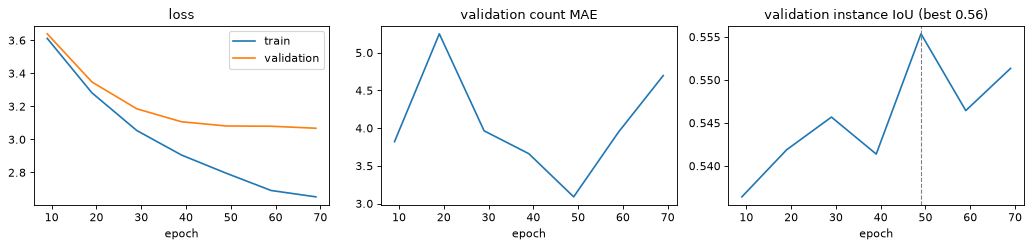

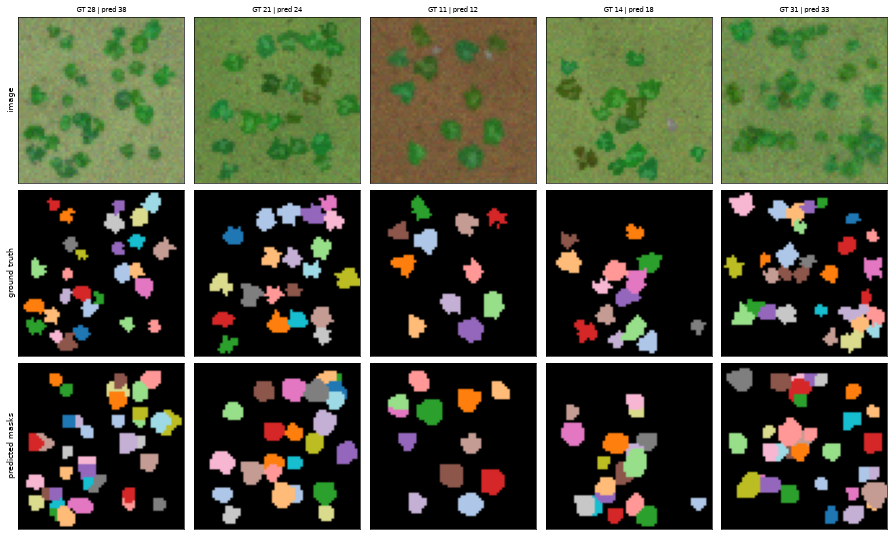

In [20]:
forest_model.eval()
with torch.no_grad():
    objectness, box_prediction, mask = forest_model(val_images_device.to(DEVICE))
detections = decode_anchor(objectness.cpu(), box_prediction.cpu(), mask.cpu(), FOREST_ANCHORS)

count_errors, count_mape, intersections, matched, total = [], [], [], 0, 0
predicted_labels = []
for sample_idx in range(n_forest_val):
    labels = per_anchor_map(detections[sample_idx])
    predicted_labels.append(labels)
    ground_truth = val_instances[sample_idx]
    gt_count = max(int(ground_truth.max()), 1)
    predicted_count = len(detections[sample_idx])
    count_errors.append(abs(predicted_count - gt_count))
    count_mape.append(abs(predicted_count - gt_count) / gt_count)
    total += gt_count
    sample_ious, sample_matched = forest_instance_scores(ground_truth, labels)
    intersections += sample_ious
    matched += sample_matched

print(f"validation count MAE {np.mean(count_errors):.2f} trees | MAPE {100*np.mean(count_mape):.0f}%"
      f" | instance IoU {np.mean(intersections):.3f}"
      f" | detection {matched}/{total} = {matched/total:.2f}")

# Baseline: always predict the training mean tree count (ignores the image).
mean_train_count = float(np.mean([max(int(i.max()), 1) for i in forest_instances[:-cut]]))
baseline_mae = float(np.mean([abs(mean_train_count - max(int(g.max()), 1)) for g in val_instances]))
print(f"mean-count baseline MAE {baseline_mae:.2f} trees (model {np.mean(count_errors):.2f})")

# Held-out test set (reported once; the checkpoint was chosen on validation).
with torch.no_grad():
    test_objectness, test_box, test_mask = forest_model(test_images_device.to(DEVICE))
test_detections = decode_anchor(test_objectness.cpu(), test_box.cpu(), test_mask.cpu(), FOREST_ANCHORS)
test_count_errors, test_count_mape, test_ious, test_matched, test_total = [], [], [], 0, 0
for sample_idx in range(n_forest_test):
    labels = per_anchor_map(test_detections[sample_idx])
    ground_truth = test_instances[sample_idx]
    gt_count = max(int(ground_truth.max()), 1)
    predicted_count = len(test_detections[sample_idx])
    test_count_errors.append(abs(predicted_count - gt_count))
    test_count_mape.append(abs(predicted_count - gt_count) / gt_count)
    test_total += gt_count
    sample_ious, sample_matched = forest_instance_scores(ground_truth, labels)
    test_ious += sample_ious
    test_matched += sample_matched
print(f"test       count MAE {np.mean(test_count_errors):.2f} trees | MAPE {100*np.mean(test_count_mape):.0f}%"
      f" | instance IoU {np.mean(test_ious):.3f}"
      f" | detection {test_matched}/{test_total} = {test_matched/test_total:.2f}")

# Training curves for the instance model: loss, count error and instance IoU.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), dpi=80)
epochs = [row[0] for row in history]
axes[0].plot(epochs, [row[1] for row in history], label="train")
axes[0].plot(epochs, [row[2] for row in history], label="validation")
axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, [row[3] for row in history]); axes[1].set_title("validation count MAE"); axes[1].set_xlabel("epoch")
best_epoch = epochs[int(np.argmax([row[4] for row in history]))]
axes[2].plot(epochs, [row[4] for row in history])
axes[2].axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
axes[2].set_title(f"validation instance IoU (best {max(row[4] for row in history):.2f})")
axes[2].set_xlabel("epoch")
plt.tight_layout()
plt.show()

# Qualitative check: image, ground truth and predicted instance masks.
fig, axes = plt.subplots(3, 5, figsize=(15, 9), dpi=60)
for sample_idx in range(5):
    axes[0, sample_idx].imshow(val_images_device[sample_idx].permute(1, 2, 0))
    axes[0, sample_idx].set_title(
        f"GT {int(val_instances[sample_idx].max())} | pred {len(detections[sample_idx])}", fontsize=8)
    axes[1, sample_idx].imshow(colorize_instances(val_instances[sample_idx]))
    axes[2, sample_idx].imshow(colorize_instances(predicted_labels[sample_idx]))
for ax, title in zip(axes[:, 0], ["image", "ground truth", "predicted masks"]):
    ax.set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


**Figure read-out.** Image / ground-truth instance masks / predicted instance masks on validation forests; dense overlapping crowns are merged or missed.

### Where does the instance model fail?

A single average hides the shape of the error. Bucketing the validation
forests by tree count shows the model is strong on **sparse** stands and
weak in **dense** canopy, where crowns overlap and are occluded; the IoU
histogram shows how many crowns are recovered almost exactly versus missed.

sparse (<=12)   n=21 | count MAE 1.90 | mean IoU 0.577
medium (13-21)  n=24 | count MAE 3.54 | mean IoU 0.590
dense (>=22)    n=11 | count MAE 4.36 | mean IoU 0.493


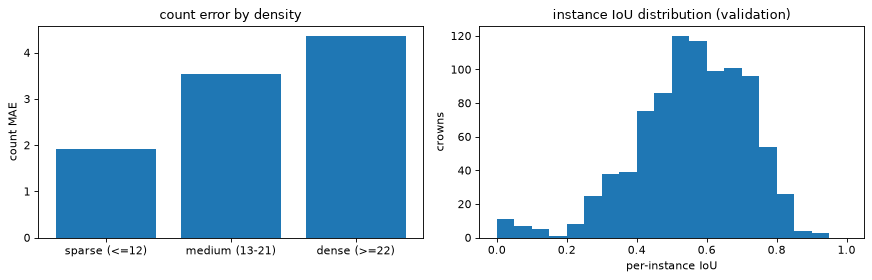

In [21]:
# Split the validation forests by density (ground-truth tree count).
buckets = {"sparse (<=12)": [], "medium (13-21)": [], "dense (>=22)": []}
bucket_ious = {key: [] for key in buckets}
for sample_idx in range(n_forest_val):
    tree_count = max(int(val_instances[sample_idx].max()), 1)
    if tree_count <= 12:
        key = "sparse (<=12)"
    elif tree_count <= 21:
        key = "medium (13-21)"
    else:
        key = "dense (>=22)"
    buckets[key].append(sample_idx)
    sample_ious, _ = forest_instance_scores(val_instances[sample_idx], predicted_labels[sample_idx])
    bucket_ious[key].extend(sample_ious)

for key in buckets:
    count = len(buckets[key])
    if count:
        mae = np.mean([count_errors[i] for i in buckets[key]])
        iou = np.mean(bucket_ious[key]) if bucket_ious[key] else 0.0
        print(f"{key:15s} n={count:2d} | count MAE {mae:.2f} | mean IoU {iou:.3f}")


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=80)
keys = list(buckets)
axes[0].bar(keys, [np.mean([count_errors[i] for i in buckets[k]]) if buckets[k] else 0 for k in keys])
axes[0].set_ylabel("count MAE"); axes[0].set_title("count error by density")
axes[1].hist([iou for values in bucket_ious.values() for iou in values], bins=20, range=(0, 1))
axes[1].set_xlabel("per-instance IoU"); axes[1].set_ylabel("crowns")
axes[1].set_title("instance IoU distribution (validation)")
plt.tight_layout()
plt.show()


**Figure read-out.** Count MAE by canopy density and the per-instance IoU histogram: error grows and IoU falls as the canopy gets denser.

### Interpreting these numbers

Detection runs at **96x96** with light sensor noise and ~40 % semi-transparent
partial cloud cover; many **cars span only ~4 px**, so a perfect detection score is physically
out of reach. The **instance model** works on 64x64 forest tiles where dense
crowns overlap heavily, some trees are almost fully hidden, and grey **boulders**
add non-tree blobs: an exact per-tree mask is simply not recoverable from the image.

So the right reading is not "the model is bad" but "these metrics quantify
robustness under realistic conditions":

- High scores on clean renders can mislead; a model that never sees noise or
  clouds can look near-perfect and fail on the first degraded acquisition.
- Clouds, haze, blur and a few pixels per object set a **ceiling** that no
  architecture can beat.
- Some errors are **irreducible** (a ~4 px car, a fully occluded crown).
- Evaluation is about an **operating point** (score threshold trades recall for
  precision), not a single number; improving the score means better resolution
  or sensors, not just a bigger network.
